In [1]:
import pytorch_lightning as pl
pl.__version__

C:\Users\Asus\anaconda3\envs\myenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


'2.6.6'

In [2]:
from torchvision import datasets

train_dataset = datasets.MNIST(root='./data', train=True, download=True)
test_dataset = datasets.MNIST(root='./data', train=False, download=True)

In [3]:
from torchvision import transforms
from torch.utils.data import DataLoader, random_split

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
])
train_dataset.transform = transform
test_dataset.transform = transform

train_size = int(0.9 * len(train_dataset))
val_size = len(train_dataset) - train_size
train_subset, val_subset = random_split(train_dataset, [train_size, val_size])

train_loader = DataLoader(train_subset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_subset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

images, labels = next(iter(train_loader))
print(images, images.shape)
print(labels)

tensor([[[[-0.4242, -0.4242, -0.4242,  ..., -0.4242, -0.4242, -0.4242],
          [-0.4242, -0.4242, -0.4242,  ..., -0.4242, -0.4242, -0.4242],
          [-0.4242, -0.4242, -0.4242,  ..., -0.4242, -0.4242, -0.4242],
          ...,
          [-0.4242, -0.4242, -0.4242,  ..., -0.4242, -0.4242, -0.4242],
          [-0.4242, -0.4242, -0.4242,  ..., -0.4242, -0.4242, -0.4242],
          [-0.4242, -0.4242, -0.4242,  ..., -0.4242, -0.4242, -0.4242]]],


        [[[-0.4242, -0.4242, -0.4242,  ..., -0.4242, -0.4242, -0.4242],
          [-0.4242, -0.4242, -0.4242,  ..., -0.4242, -0.4242, -0.4242],
          [-0.4242, -0.4242, -0.4242,  ..., -0.4242, -0.4242, -0.4242],
          ...,
          [-0.4242, -0.4242, -0.4242,  ..., -0.4242, -0.4242, -0.4242],
          [-0.4242, -0.4242, -0.4242,  ..., -0.4242, -0.4242, -0.4242],
          [-0.4242, -0.4242, -0.4242,  ..., -0.4242, -0.4242, -0.4242]]],


        [[[-0.4242, -0.4242, -0.4242,  ..., -0.4242, -0.4242, -0.4242],
          [-0.4242, -0.424

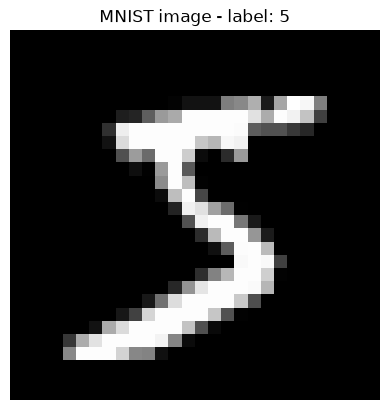

In [4]:
import matplotlib.pyplot as plt

image, label = train_dataset[0]
image = image * 0.3081 + 0.1307
plt.imshow(image.squeeze(0), cmap="gray")
plt.title(f"MNIST image - label: {label}")
plt.axis("off")
plt.show()

In [5]:
import pytorch_lightning as pl
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchmetrics import Accuracy


class CNN(pl.LightningModule):
    def __init__(self, learning_rate=0.01):
        super().__init__()
        self.learning_rate = learning_rate
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=32, kernel_size=(3, 3))
        self.pool = nn.MaxPool2d(kernel_size=(2, 2))
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=(3, 3))
        self.dropout = nn.Dropout(p=0.5)
        self.fc1 = nn.Linear(64 * 5 * 5, 100)
        self.fc2 = nn.Linear(100, 10)
        self.train_accuracy = Accuracy(task="multiclass", num_classes=10)
        self.val_accuracy = Accuracy(task="multiclass", num_classes=10)
        self.test_accuracy = Accuracy(task="multiclass", num_classes=10)
        self.train_accuracies = []
        self.val_accuracies = []
        self.criterion = nn.CrossEntropyLoss()

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = self.dropout(x)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

    def training_step(self, batch, batch_idx):
        x, y = batch
        y_hat = self(x)
        self.train_accuracy.update(y_hat, y)
        return self.criterion(y_hat, y)

    def on_train_epoch_end(self):
        accuracy = self.train_accuracy.compute()
        self.train_accuracies.append(float(accuracy.detach().cpu()))
        self.log("train_accuracy", accuracy, prog_bar=True)
        self.train_accuracy.reset()

    def validation_step(self, batch, batch_idx):
        x, y = batch
        y_hat = self(x)
        loss = self.criterion(y_hat, y)
        self.val_accuracy.update(y_hat, y)
        self.log("val_loss", loss, on_step=False, on_epoch=True, prog_bar=True)
        return loss

    def on_validation_epoch_end(self):
        accuracy = self.val_accuracy.compute()
        self.val_accuracies.append(float(accuracy.detach().cpu()))
        self.log("val_accuracy", accuracy, prog_bar=True)
        self.val_accuracy.reset()

    def test_step(self, batch, batch_idx):
        x, y = batch
        y_hat = self(x)
        loss = self.criterion(y_hat, y)
        self.test_accuracy.update(y_hat, y)
        self.log("test_loss", loss, on_step=False, on_epoch=True)
        return loss

    def on_test_epoch_end(self):
        self.log("test_accuracy", self.test_accuracy.compute())
        self.test_accuracy.reset()

    def configure_optimizers(self):
        return optim.SGD(self.parameters(), lr=self.learning_rate, momentum=0.9)


model = CNN()
print(model)

CNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
  (pool): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
  (dropout): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=1600, out_features=100, bias=True)
  (fc2): Linear(in_features=100, out_features=10, bias=True)
  (train_accuracy): MulticlassAccuracy()
  (val_accuracy): MulticlassAccuracy()
  (test_accuracy): MulticlassAccuracy()
  (criterion): CrossEntropyLoss()
)


In [6]:
import torch

model = CNN()
trainer = pl.Trainer(
    max_epochs=10,
    accelerator="gpu" if torch.cuda.is_available() else "cpu",
    devices=1,
    num_sanity_val_steps=0,
)

GPU available: False, used: False


TPU available: False, using: 0 TPU cores


C:\Users\Asus\anaconda3\envs\myenv\Lib\site-packages\pytorch_lightning\trainer\connectors\logger_connector\logger_connector.py:76: Starting from v1.9.0, `tensorboardX` has been removed as a dependency of the `pytorch_lightning` package, due to potential conflicts with other packages in the ML ecosystem. For this reason, `logger=True` will use `CSVLogger` as the default logger, unless the `tensorboard` or `tensorboardX` packages are found. Please `pip install lightning[extra]` or one of them to enable TensorBoard support by default
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


In [ ]:
trainer.fit(model, train_loader, val_loader)
test_results = trainer.test(model, test_loader)
test_accuracy = test_results[0]["test_accuracy"]
print(f"Test accuracy: {test_accuracy:.4f}")
print("Training accuracy by epoch:", [round(value, 4) for value in model.train_accuracies])
print("Validation accuracy by epoch:", [round(value, 4) for value in model.val_accuracies])

import matplotlib.pyplot as plt

epochs = range(1, len(model.train_accuracies) + 1)
plt.figure(figsize=(8, 5))
plt.plot(epochs, model.train_accuracies, marker="o", label="Training accuracy")
plt.plot(epochs, model.val_accuracies, marker="s", label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training and Validation Accuracy over 10 Epochs")
plt.xticks(epochs)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


┏━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name           ┃ Type               ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ conv1          │ Conv2d             │    320 │ train │     0 │
│ 1 │ pool           │ MaxPool2d          │      0 │ train │     0 │
│ 2 │ conv2          │ Conv2d             │ 18.5 K │ train │     0 │
│ 3 │ dropout        │ Dropout            │      0 │ train │     0 │
│ 4 │ fc1            │ Linear             │  160 K │ train │     0 │
│ 5 │ fc2            │ Linear             │  1.0 K │ train │     0 │
│ 6 │ train_accuracy │ MulticlassAccuracy │      0 │ train │     0 │
│ 7 │ val_accuracy   │ MulticlassAccuracy │      0 │ train │     0 │
│ 8 │ test_accuracy  │ MulticlassAccuracy │      0 │ train │     0 │
│ 9 │ criterion      │ CrossEntropyLoss   │      0 │ train │     0 │
└───┴────────────────┴────────────────────┴────────┴───────┴───────┘

Trainable params: 179 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 179 K                                                                                                
Total estimated model params size (MB): 0.720                                                                      
Modules in train mode: 10                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Seed set to 42


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


┏━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name           ┃ Type               ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ conv1          │ Conv2d             │    320 │ train │     0 │
│ 1 │ pool           │ MaxPool2d          │      0 │ train │     0 │
│ 2 │ conv2          │ Conv2d             │ 18.5 K │ train │     0 │
│ 3 │ dropout        │ Dropout            │      0 │ train │     0 │
│ 4 │ fc1            │ Linear             │  160 K │ train │     0 │
│ 5 │ fc2            │ Linear             │  1.0 K │ train │     0 │
│ 6 │ train_accuracy │ MulticlassAccuracy │      0 │ train │     0 │
│ 7 │ val_accuracy   │ MulticlassAccuracy │      0 │ train │     0 │
│ 8 │ test_accuracy  │ MulticlassAccuracy │      0 │ train │     0 │
│ 9 │ criterion      │ CrossEntropyLoss   │      0 │ train │     0 │
└───┴────────────────┴────────────────────┴────────┴───────┴───────┘

... (10 outputs left out)

┏━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name           ┃ Type               ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ conv1          │ Conv2d             │    320 │ train │     0 │
│ 1 │ pool           │ MaxPool2d          │      0 │ train │     0 │
│ 2 │ conv2          │ Conv2d             │ 18.5 K │ train │     0 │
│ 3 │ dropout        │ Dropout            │      0 │ train │     0 │
│ 4 │ fc1            │ Linear             │  160 K │ train │     0 │
│ 5 │ fc2            │ Linear             │  1.0 K │ train │     0 │
│ 6 │ train_accuracy │ MulticlassAccuracy │      0 │ train │     0 │
│ 7 │ val_accuracy   │ MulticlassAccuracy │      0 │ train │     0 │
│ 8 │ test_accuracy  │ MulticlassAccuracy │      0 │ train │     0 │
│ 9 │ criterion      │ CrossEntropyLoss   │      0 │ train │     0 │
└───┴────────────────┴────────────────────┴────────┴───────┴───────┘

Trainable params: 179 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 179 K                                                                                                
Total estimated model params size (MB): 0.720                                                                      
Modules in train mode: 10                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

`Trainer.fit` stopped: `max_epochs=10` reached.



Learning rate: 0.003
Epoch | Training accuracy | Validation accuracy
    1 |            0.9005 |              0.9758
    2 |            0.9708 |              0.9845
    3 |            0.9772 |              0.9857
    4 |            0.9816 |              0.9882
    5 |            0.9845 |              0.9905
    6 |            0.9851 |              0.9898
    7 |            0.9864 |              0.9893
    8 |            0.9874 |              0.9902
    9 |            0.9887 |              0.9918
   10 |            0.9898 |              0.9913


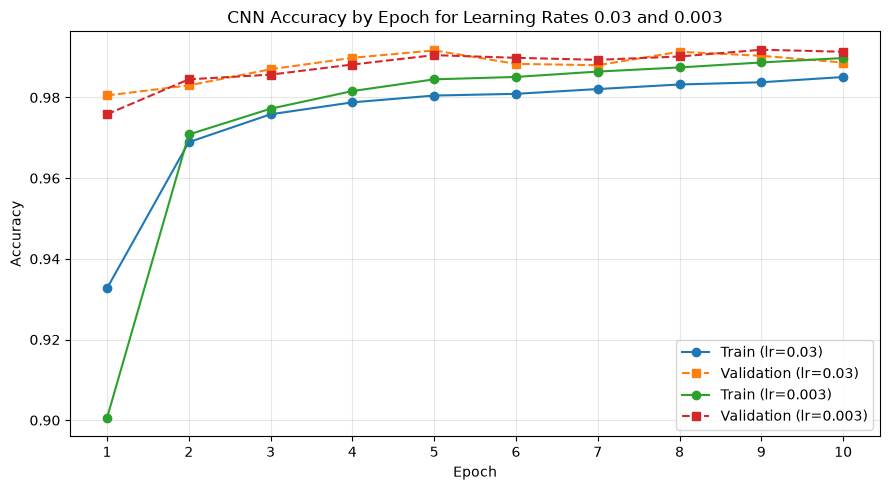

In [8]:
import matplotlib.pyplot as plt

comparison_rates = (0.03, 0.003)
comparison_results = {}
for learning_rate in comparison_rates:
    pl.seed_everything(42, workers=True)
    comparison_model = CNN(learning_rate=learning_rate)
    comparison_trainer = pl.Trainer(
        max_epochs=10,
        accelerator="gpu" if torch.cuda.is_available() else "cpu",
        devices=1,
        num_sanity_val_steps=0,
    )
    comparison_trainer.fit(comparison_model, train_loader, val_loader)
    comparison_results[learning_rate] = {
        "train": comparison_model.train_accuracies.copy(),
        "validation": comparison_model.val_accuracies.copy(),
    }

    print(f"\nLearning rate: {learning_rate:g}")
    print("Epoch | Training accuracy | Validation accuracy")
    for epoch, (train_accuracy, val_accuracy) in enumerate(
        zip(comparison_model.train_accuracies, comparison_model.val_accuracies),
        start=1,
    ):
        print(f"{epoch:5d} | {train_accuracy:17.4f} | {val_accuracy:19.4f}")

comparison_epochs = range(1, 11)
plt.figure(figsize=(9, 5))
for learning_rate, results in comparison_results.items():
    plt.plot(comparison_epochs, results["train"], marker="o", label=f"Train (lr={learning_rate:g})")
    plt.plot(
        comparison_epochs,
        results["validation"],
        marker="s",
        linestyle="--",
        label=f"Validation (lr={learning_rate:g})",
    )
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Accuracy by Epoch for Learning Rates 0.03 and 0.003")
plt.xticks(comparison_epochs)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()